# Blood glucose — overall effects by stage comparison

Posterior contrasts for **Baseline**, **Vehicle − Baseline**, and **Empa − Vehicle**, averaged equally across the other modeled factor. The original model includes genotype and sex but **does not include age**, so age effects are not estimable from this fit.

All effects are on the **log blood-glucose scale** (the fitted linear predictor). For changes, the contrasts are differences in log-stage changes, not differences in absolute mmol/L changes.

## Imports and fitted model

In [1]:
import arviz as az
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from kidney.paths import RESULTS_DIR, PLOT_DIR
from kidney.plotting import forestplot_oz
from kidney.sign_probs import get_sign_probs, get_signif

# After adding the helper functions in the next section to kidney/contrasts.py:
from kidney.contrasts import get_t_groups_glucose, get_overall_effects_glucose

plt.rcParams['pdf.fonttype'] = 42
az.rcParams['data.load'] = 'eager'

idata = az.from_netcdf(RESULTS_DIR / 'idata_blood_glucose.nc')
print(list(idata.posterior.data_vars))

['sigma', 'Intercept', 'stage', 'gtyp', 'sex', 'stage:gtyp', 'stage:sex', 'gtyp|rat_sigma', 'gtyp|rat', 'mu']


## Functions to add to `kidney/contrasts.py`

Copy the following definitions to your existing `kidney/contrasts.py` file **before running the import above**. They are deliberately separate from the existing `get_t_groups()` and `get_overall_effects()` because this glucose model has no age term and uses a single `stage` factor. They extract posterior draws without collapsing `chain` and `draw`.

## Posterior contrasts

For each comparison, first obtain the **group-level posterior draws**, then take the desired within-group stage difference, and finally calculate genotype and sex contrasts. This preserves posterior correlations between stages. Baseline is the genotype/sex effect on baseline log glucose, whereas the other two panels show **differences in the genotype/sex effects on stage changes**.

In [2]:
from kidney.contrasts import subtract_t_groups_glucose

baseline = get_t_groups_glucose(idata, stage="baseline")
vehicle = get_t_groups_glucose(idata, stage="vehicle")
empa = get_t_groups_glucose(idata, stage="empa")

stage_groups = {
    "Baseline": baseline,
    "Vehicle − Baseline": subtract_t_groups_glucose(vehicle, baseline),
    "Empa − Vehicle": subtract_t_groups_glucose(empa, vehicle),
}

ts = {
    comparison: get_overall_effects_glucose(groups)
    for comparison, groups in stage_groups.items()
}

# Age is not a model parameter; it cannot be estimated from this fit.
for comparison, effects in ts.items():
    print(comparison, {name: round(float(value.mean()), 3) for name, value in effects.items()})

Baseline {'fa/fa - fa/+': 1.485, 'male - female': 0.171}
Vehicle − Baseline {'fa/fa - fa/+': -0.89, 'male - female': -0.011}
Empa − Vehicle {'fa/fa - fa/+': 0.024, 'male - female': -0.047}


## Plot overall effects

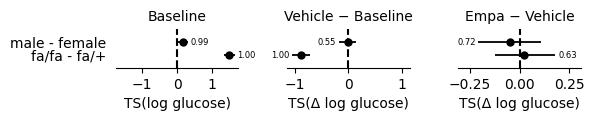

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(6, 0.5), sharey=True)
plt.subplots_adjust(wspace=0.4)

for ax, (comparison, effects) in zip(axes, ts.items()):
    forestplot_oz(ax, effects, sign_probs=True)
    ax.set_title(comparison, fontsize=10)
    ax.spines[["top", "right", "left"]].set_visible(False)

for ax in axes[1:]:
    ax.tick_params(axis="y", left=False, labelleft=False)

axes[0].set_xlabel("TS(log glucose)")
axes[1].set_xlabel("TS(\u0394 log glucose)")
axes[2].set_xlabel("TS(\u0394 log glucose)")

fig.savefig(PLOT_DIR / "ts_bloodGlucose_overall_stage_comparisons.pdf",
            bbox_inches="tight", transparent=True)

## Sign probabilities and significance

In [4]:
sp_all = pd.concat(
    {
        comparison: pd.DataFrame({
            "sign_probability": (probs := get_sign_probs(effects)),
            "significance": {name: get_signif(prob) for name, prob in probs.items()},
        })
        for comparison, effects in ts.items()
    },
    names=["comparison", "effect"],
)

# Age effects are unavailable because age was excluded from the fitted model.
display(sp_all)
# sp_all.to_csv(PLOT_DIR / "ts_bloodGlucose_overall_stage_comparisons.csv")

sign_probability significance
comparison         effect                                      
Baseline           fa/fa - fa/+            1.00000            *
                   male - female           0.99325            *
Vehicle − Baseline fa/fa - fa/+            0.00000            *
                   male - female           0.45350             
Empa − Vehicle     fa/fa - fa/+            0.63125             
                   male - female           0.27700

## Empa − Vehicle glucose change by genotype

Posterior stage changes for each genotype, averaged equally over female and male rats, plus the equally weighted overall change. These are changes in **log glucose**, not genotype contrasts.

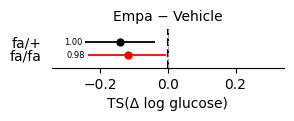

In [15]:
change = stage_groups["Empa − Vehicle"]

ts_empa_vehicle_by_gtyp = {
    "fa/fa": (change["fa/fa:female"] + change["fa/fa:male"]) / 2,
    "fa/+": (change["fa/+:female"] + change["fa/+:male"]) / 2,
}
# ts_empa_vehicle_by_gtyp["Overall"] = (
#     ts_empa_vehicle_by_gtyp["fa/fa"] + ts_empa_vehicle_by_gtyp["fa/+"]
# ) / 2

fig, ax = plt.subplots(figsize=(3, .5))
forestplot_oz(ax, ts_empa_vehicle_by_gtyp, sign_probs=True)
ax.axvline(0, color="0.6", lw=0.8, ls="--", zorder=0)
ax.set_title("Empa − Vehicle", fontsize=10)
ax.set_xlabel("TS(\u0394 log glucose)")
ax.spines[["top", "right", "left"]].set_visible(False)

fig.savefig(PLOT_DIR / "ts_bloodGlucose_empa_minus_vehicle_by_gtyp.pdf",
            bbox_inches="tight", transparent=True)


In [13]:
probs = get_sign_probs(ts_empa_vehicle_by_gtyp)
sp_empa_vehicle_by_gtyp = pd.DataFrame({
    "sign_probability": probs,
    "significance": {name: get_signif(p) for name, p in probs.items()},
})
display(sp_empa_vehicle_by_gtyp)


,sign_probability,significance
fa/fa,0.02000,*
fa/+,0.00325,*
